# Практическое занятие №3-4
**Дисциплина:** «Алгоритмы машинного обучения для решения прикладных задач»

Ниже — разбор примера из методических указаний (бинарная классификация ирисов логистической регрессией), затем — решение задания: классификация красного вина на «хорошее» и «некачественное».

# Основные понятия и примеры прикладных задач

# Используемые пакеты

In [1]:
try:
    import google.colab
    IN_COLAB = True
except:
    IN_COLAB = False

if IN_COLAB:
    !wget -q -O requirements.txt 
    !pip install -q -r requirements.txt

In [2]:
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Ирисы Фишера
Выборка взята отсюда: https://archive.ics.uci.edu/ml/datasets/iris

## Загрузка выборки

In [3]:
try:
    dataset = pd.read_csv('https://raw.githubusercontent.com/andriygav/MachineLearningSeminars/master/sem1/data/iris.csv',
                          header=None,
                          names=['длина чашелистика', 'ширина чашелистика',
                                 'длина лепестка', 'ширина лепестка', 'класс'])
except Exception:   # нет доступа к сети — тот же набор из sklearn
    from sklearn.datasets import load_iris
    _iris = load_iris()
    dataset = pd.DataFrame(_iris.data, columns=['длина чашелистика', 'ширина чашелистика', 'длина лепестка', 'ширина лепестка'])
    dataset['класс'] = ['Iris-' + _iris.target_names[t] for t in _iris.target]
dataset.sample(5, random_state=0)

,длина чашелистика,ширина чашелистика,длина лепестка,ширина лепестка,класс
114,5.8,2.8,5.1,2.4,Iris-virginica
62,6.0,2.2,4.0,1.0,Iris-versicolor
33,5.5,4.2,1.4,0.2,Iris-setosa
107,7.3,2.9,6.3,1.8,Iris-virginica
7,5.0,3.4,1.5,0.2,Iris-setosa


## Начало работы с данными
1. Определить множество объектов:
    * Определить размер выборки
    * Определить признаки, которыми описываются объекты
2. Определить множество ответов
3. Определить тип задачи машинного обучения
6. ...

### Множество объектов
В данной задачи множество объектов описывается $n=4$ признаками:
1. Длина чашелистика
2. Ширина чашелистика
3. Длина лепестка
4. Ширина лепестка

In [4]:
print('Размер выборки составляет l={} объектов.'.format(len(dataset)))

Размер выборки составляет l=150 объектов.


Все признаки являются вещественными признаками. Формально объекты $\mathbf{X}$ представляються в следующем виде:
$$\mathbf{X} \in \mathbb{R}^{l\times n},$$
где $l$ число объектов, а $n$ число признаков.

Получаем, что $\mathbf{X}$ это некоторая вещественная матрица размера $l\times n$.

### Множество ответов
В данной задаче множество ответов состоит из трех элементов:
1. Iris-virginica
2. Iris-versicolor
3. Iris-setosa

### Задача машинного обучения
В нашем случае, так как мощность множества $|\mathbf{y}|=3 \ll l=150$ получаем задачу классификации на $M=3$ класса.

## Анализ данных
Сначала проэктируем все объекты на двумерные плоскости, для упрощения анализа

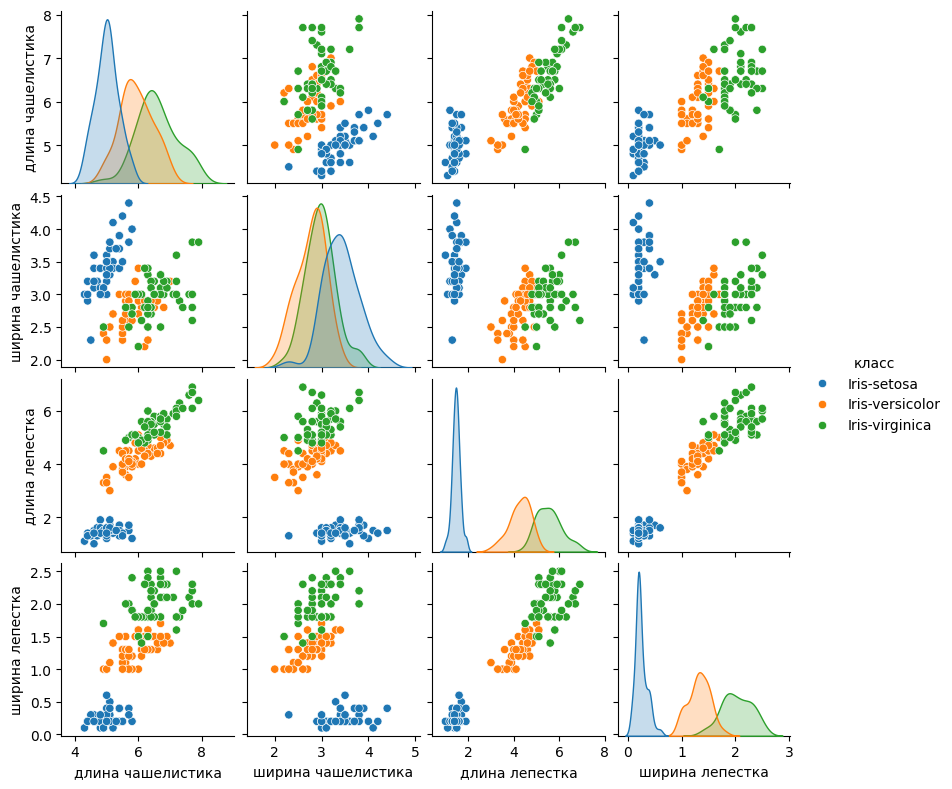

In [5]:
sns.pairplot(dataset, hue='класс', height=2)
plt.show()

Из рисунка видно, что класс синих точек (Iris-setosa) легко отделяется от двух других цветов. Оранджевые и зеленные точки отделяются не так просто в каждой из проэкций, но все равно можно провести прямую, которая отделит оранджевые точки от зеленых.

## Построение модели
### Преобразование данных
Как было сказано ранее нам требуется решить задачу классификации на 3 класса. Но для наглядноси рассмотрим бинарную классификацию (классификацию на несколько классов рассмотрим в следующей лекции).

Чтобы исходную задачу преобразовать в задачу бинарной классификации уберем из выборки все объекта класса Iris-setosa.

In [6]:
binary_dataset = dataset.drop(index=dataset.index[dataset['класс'] == 'Iris-setosa'])

Классы закодируем целыми числами $-1$ и $1$.

In [7]:
binary_dataset = binary_dataset.copy()
binary_dataset['класс'] = binary_dataset['класс'].map({'Iris-versicolor': -1, 'Iris-virginica': 1})

Получаем задачу бинарной классификации.

### Модель алгоритмов

Модель алгоритмов $\mathfrak{F}$ в машинном обучении это некоторое множество функций, которые действуют из множества объектов в множество ответов, в нашем случае:
$$\mathfrak{F} = \{f| f: \mathbb{R}^n \to \{-1, 1\}, \text{еще какие-то ограничения}\},$$
обычно $\mathfrak{F}$ это некоторое параметрическое семество функций, тоесть разные функции $f$ отличаются друг от друга только каким-то параметром. Простым примером параметрическим семейством функций для задачи бинарной классификации является семейство линейный классификатор:
$$\mathfrak{F}_{bcl} = \left\{f\bigr(\theta, \mathbf{x}\bigr)=\text{sign}\bigr(\theta^{\mathsf{T}}\mathbf{x}\bigr)\bigr| \theta \in \mathbb{R}^{n} \right\}.$$


### Функция потерь

Машиное обучение это всегда выбор функции из множества $\mathfrak{F}$. Чтобы выбрать функцию, нужен некоторый критерий по которому она выбирается, то есть нужно упоррядочить все функции от худшей к лучшей. Для этого построем функционал $\mathcal{L}$, который каждой функции $f \in \mathfrak{F}$ ставит в соответствии число из $\mathbb{R}_+$. В машинном обучении обычно функционал качества водиться как некоторая ошибка на выборке. В общем виде функционал качества можно представить в следующем виде:
$$\mathcal{L}\bigr(f, \mathbf{X}, \mathbf{y}\bigr) = \sum_{i=1}^l\mathcal{q}\bigr(f, \mathbf{x}_i, y_i\bigr),$$
где $q$ некоторая функция ошибки на некотором объекте $\mathbf{x}$. Функционал качества $\mathcal{L}$ называется эмперическим риском.

### Оптимизационная задача

Далее нужно поставить задачу оптимизации для выбора $f \in \mathfrak{F}$. Здесь все просто, просто минимизируем эмперический риск:
$$\hat{f} = \arg \min_{f \in \mathfrak{F}} \mathcal{L}\bigr(f, \mathbf{X}, \mathbf{y}\bigr).$$

Важно! В результе функция $\hat{f}$ зависит от выборки $\left(\mathbf{X}, \mathbf{y}\right)$, то есть для разных наборов данных оптимальная функция будет различная.

Вернемся к нашей задаче. В нашем случае функционал качества будет иметь следующий вид:
$$\mathcal{L}\bigr(\theta, \mathbf{X}, \mathbf{y}\bigr) = \sum_{i=1}^l\bigr[f\bigr(\theta, \mathbf{x}_i\bigr) \not= y_i\bigr],$$
и оптимизационная задача переписывается в виде:
$$\hat{\theta} = \arg \min_{\theta \in \mathbb{R}^n} \sum_{i=1}^l\bigr[f\bigr(\theta, \mathbf{x}_i\bigr) \not= y_i\bigr].$$

И на самом деле в дальнейшем будем решать иммено такие задачи, на поиск оптимального параметра. Само решение задачи линейной бинарной классификации будет на следующей лекции. Сейчас используемся библиотеками для решения данной задачи. Далее в примере будет найден параметр $\hat{\theta}$ не как решение непосредственно этой оптимизационной задачи, а немного измененной, но об этом позже в следующей лекции.

### Поиск оптимального вектора параметров
Перейдем к двум матрицам:
1. Матрице объектов $\mathbf{X} \in \mathbb{R}^{l\times (n+1)}$
2. Вектору ответов $\mathbf{y} \in \{-1,1\}^l$

Заметим, что объекты мы погрузили в пространство более большой размерности, добавив еще один признак, который у всех объектов будет равен $1$.

In [8]:
X = binary_dataset.iloc[:, binary_dataset.columns != 'класс'].values
y = binary_dataset.iloc[:, binary_dataset.columns == 'класс'].values.reshape(-1)
X = np.array(np.hstack([X, np.ones([len(X), 1])]), dtype=np.float64)
y = np.array(y, dtype=np.int64)

In [9]:
model = LogisticRegression(random_state=0, max_iter=2000)
_ = model.fit(X, y)

Получаем вектор оптимальных параметров $\hat{\theta}$

In [10]:
model.coef_

array([[-3.94857799e-01, -5.12236925e-01,  2.93150207e+00,
         2.41616121e+00, -1.17463494e-03]])

Загрузите файл winequality-red.csv (с помощью pd.read_csv).

Последний столбец отвечает за качество вина. Будем считать, что хорошее вино начинается с цифры 7 и выше. 
Остальное вино будем счиатать некачественным.

Сделайте классификацию вина по данному датасету. Два класса "Хорошее" и "Не качественное". 
Результатом будем считать уравнение гиперповерхности на гиперпространстве параметров, отделяющее один класс от другого. 

---
# Решение задания: классификация красного вина

Загрузите файл `winequality-red.csv`. Последний столбец отвечает за качество вина. Хорошее вино — оценка 7 и выше, остальное — некачественное.
Сделайте классификацию вина на два класса: «Хорошее» и «Некачественное». Результат — уравнение гиперповерхности в пространстве признаков,
отделяющей один класс от другого.

In [11]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

wine = pd.read_csv('winequality-red.csv')
print(wine.shape)
wine.head()

(1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [12]:
wine.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [13]:
wine['класс'] = np.where(wine['quality'] >= 7, 1, -1)     # 1 — «Хорошее», -1 — «Некачественное» (как в примере)
print(wine['класс'].value_counts().rename({1: 'Хорошее', -1: 'Некачественное'}))
print('Доля хороших вин:', round((wine['класс'] == 1).mean(), 3))

класс
Некачественное    1382
Хорошее            217
Name: count, dtype: int64
Доля хороших вин: 0.136


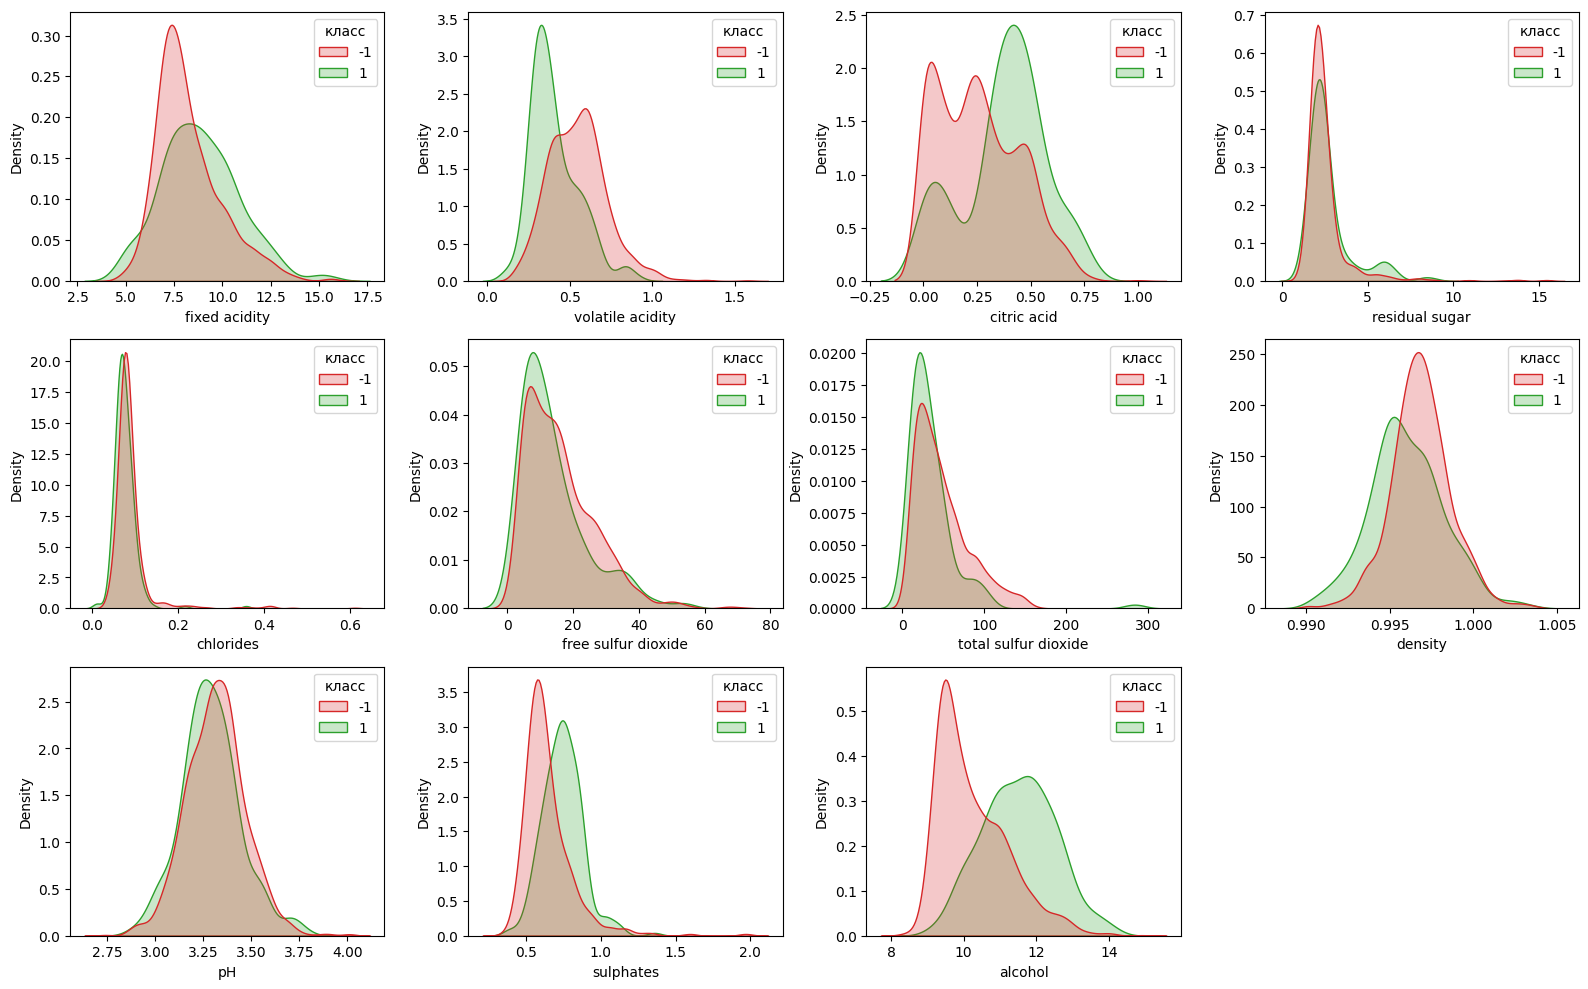

In [14]:
feature_names = list(wine.columns[:11])
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), feature_names):
    sns.kdeplot(data=wine, x=col, hue='класс', common_norm=False, fill=True, ax=ax, palette={1: 'tab:green', -1: 'tab:red'})
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

Классы несбалансированы (≈ 13.6 % хороших вин). Сильнее всего классы различаются по содержанию алкоголя, летучей кислотности,
сульфатам и лимонной кислоте. Признаки имеют разные масштабы, поэтому перед обучением выполним стандартизацию.

### Подготовка данных и обучение логистической регрессии

In [15]:
X = wine[feature_names].values
y = wine['класс'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

model = LogisticRegression(random_state=0, max_iter=2000)
_ = model.fit(X_train_s, y_train)

In [16]:
def report(m, Xs, y_true, name):
    pred = m.predict(Xs)
    return {'модель': name, 'accuracy': accuracy_score(y_true, pred),
            'precision': precision_score(y_true, pred, pos_label=1), 'recall': recall_score(y_true, pred, pos_label=1),
            'F1': f1_score(y_true, pred, pos_label=1), 'ROC AUC': roc_auc_score(y_true, m.decision_function(Xs))}

print(classification_report(y_test, model.predict(X_test_s), target_names=['Некачественное', 'Хорошее']))

                precision    recall  f1-score   support

Некачественное       0.90      0.92      0.91       346
       Хорошее       0.41      0.33      0.37        54

      accuracy                           0.84       400
     macro avg       0.65      0.63      0.64       400
  weighted avg       0.83      0.84      0.84       400



In [17]:
model_bal = LogisticRegression(random_state=0, max_iter=2000, class_weight='balanced').fit(X_train_s, y_train)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
res = pd.DataFrame([report(model, X_test_s, y_test, 'LogisticRegression'),
                    report(model_bal, X_test_s, y_test, "LogisticRegression(class_weight='balanced')")]).round(3)
res['CV accuracy (5 fold)'] = [cross_val_score(LogisticRegression(max_iter=2000, class_weight=cw), X_train_s, y_train, cv=cv).mean().round(3)
                               for cw in [None, 'balanced']]
res

,модель,accuracy,precision,recall,F1,ROC AUC,CV accuracy (5 fold)
0,LogisticRegression,0.845,0.409,0.333,0.367,0.83,0.885
1,LogisticRegression(class_weight='balanced'),0.772,0.333,0.685,0.448,0.83,0.803


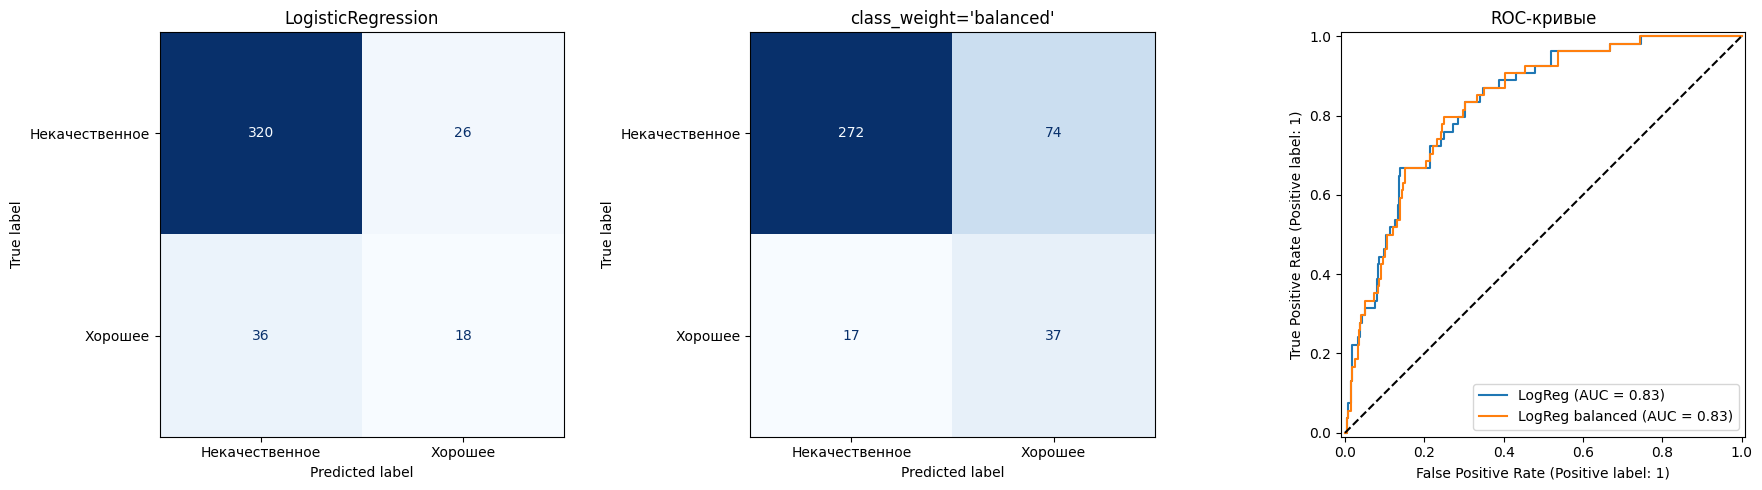

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (m, t) in zip(axes[:2], [(model, 'LogisticRegression'), (model_bal, "class_weight='balanced'")]):
    ConfusionMatrixDisplay.from_predictions(y_test, m.predict(X_test_s), display_labels=['Некачественное', 'Хорошее'],
                                            cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(t)
RocCurveDisplay.from_estimator(model, X_test_s, y_test, ax=axes[2], name='LogReg')
RocCurveDisplay.from_estimator(model_bal, X_test_s, y_test, ax=axes[2], name='LogReg balanced')
axes[2].plot([0, 1], [0, 1], 'k--'); axes[2].set_title('ROC-кривые')
plt.tight_layout(); plt.show()

### Уравнение разделяющей гиперповерхности

Логистическая регрессия относит объект к классу «Хорошее», если $\theta_0 + \sum_i \theta_i x_i > 0$.
Значит, граница классов — **гиперплоскость** $\theta_0 + \theta_1 x_1 + \dots + \theta_{11} x_{11} = 0$ в 11-мерном пространстве признаков.
Модель обучена на стандартизованных признаках $z_i = (x_i - \mu_i)/\sigma_i$, поэтому пересчитаем коэффициенты в исходные единицы:
$\theta_i = w_i / \sigma_i$, $\theta_0 = w_0 - \sum_i w_i \mu_i / \sigma_i$.

In [19]:
w, w0 = model.coef_[0], model.intercept_[0]
theta = w / scaler.scale_
theta0 = w0 - np.sum(w * scaler.mean_ / scaler.scale_)

coef_table = pd.DataFrame({'признак': feature_names, 'коэф. (станд. признаки)': w, 'коэф. (исходные единицы)': theta}) \
               .sort_values('коэф. (станд. признаки)', key=abs, ascending=False).round(4)
display(coef_table)

terms = ' '.join(f"{'+' if t >= 0 else '-'} {abs(t):.4f}*[{n}]" for t, n in zip(theta, feature_names))
print('Уравнение разделяющей гиперплоскости (исходные единицы):')
print(f'{theta0:.4f} {terms} = 0')

,признак,коэф. (станд. признаки),коэф. (исходные единицы)
10,alcohol,0.9575,0.9128
0,fixed acidity,0.6708,0.3759
9,sulphates,0.6289,3.8674
7,density,-0.6150,-326.7453
1,volatile acidity,-0.4470,-2.5328
3,residual sugar,0.4028,0.2949
6,total sulfur dioxide,-0.3909,-0.0119
4,chlorides,-0.3478,-7.5277
2,citric acid,0.1627,0.8382
5,free sulfur dioxide,0.0426,0.0041


Уравнение разделяющей гиперплоскости (исходные единицы):
308.4739 + 0.3759*[fixed acidity] - 2.5328*[volatile acidity] + 0.8382*[citric acid] + 0.2949*[residual sugar] - 7.5277*[chlorides] + 0.0041*[free sulfur dioxide] - 0.0119*[total sulfur dioxide] - 326.7453*[density] + 0.1646*[pH] + 3.8674*[sulphates] + 0.9128*[alcohol] = 0


In [20]:
# Проверка: знак левой части уравнения совпадает с предсказанием модели
lhs = theta0 + X_test @ theta
print('Совпадение с model.predict:', np.mean(np.where(lhs > 0, 1, -1) == model.predict(X_test_s)))

Совпадение с model.predict: 1.0


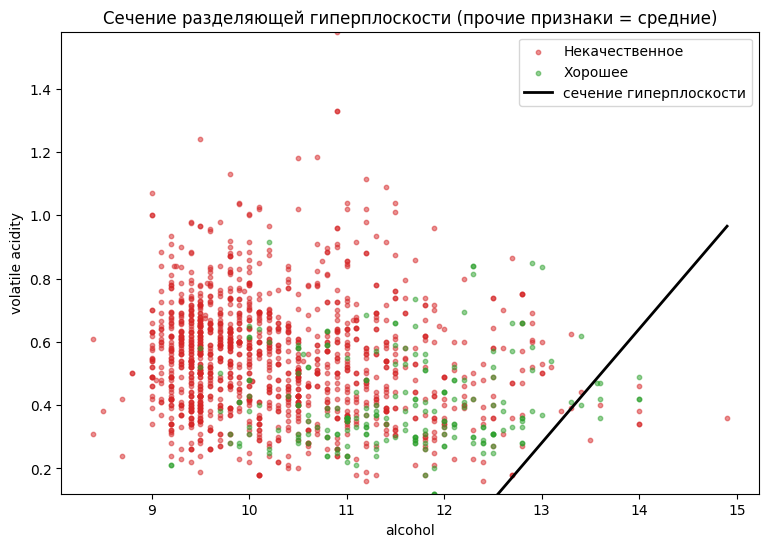

In [21]:
# Визуализация проекции на два самых значимых признака (остальные зафиксированы на средних значениях)
i, j = feature_names.index('alcohol'), feature_names.index('volatile acidity')
xx = np.linspace(wine['alcohol'].min(), wine['alcohol'].max(), 100)
others = theta0 + sum(theta[k] * X_train[:, k].mean() for k in range(11) if k not in (i, j))
yy = -(others + theta[i] * xx) / theta[j]
plt.figure(figsize=(9, 6))
for cls, c, lab in [(-1, 'tab:red', 'Некачественное'), (1, 'tab:green', 'Хорошее')]:
    m = wine['класс'] == cls
    plt.scatter(wine.loc[m, 'alcohol'], wine.loc[m, 'volatile acidity'], s=10, c=c, alpha=0.5, label=lab)
plt.plot(xx, yy, 'k', lw=2, label='сечение гиперплоскости')
plt.ylim(wine['volatile acidity'].min(), wine['volatile acidity'].max())
plt.xlabel('alcohol'); plt.ylabel('volatile acidity'); plt.legend()
plt.title('Сечение разделяющей гиперплоскости (прочие признаки = средние)'); plt.show()

## Выводы по ПР 3-4

1. Задача сведена к бинарной классификации: «Хорошее» вино (quality ≥ 7, ≈ 13.6 % выборки) и «Некачественное».
2. Логистическая регрессия на стандартизованных признаках достигает на тестовой выборке accuracy 0.845 и ROC AUC 0.83
   (accuracy на 5-кратной кросс-валидации — 0.885). Однако из-за дисбаланса классов полнота по классу «Хорошее» невысока (0.33):
   модель пропускает две трети хороших вин. Взвешивание классов (`class_weight='balanced'`) повышает полноту до 0.69 и F1 с 0.37 до 0.45
   ценой снижения accuracy до 0.77 — выбор варианта зависит от того, какая ошибка дороже.
3. Получено явное уравнение разделяющей гиперплоскости в исходных единицах признаков (проверено: знак левой части уравнения
   совпадает с предсказанием модели для всех объектов). По стандартизованным коэффициентам наибольший положительный вклад
   в вероятность «хорошего» вина вносят **алкоголь**, фиксированная кислотность и **сульфаты**, наибольший отрицательный —
   **плотность**, **летучая кислотность**, общее содержание диоксида серы и хлориды. Это согласуется с разведочным анализом.
   Большие по модулю коэффициенты при плотности в исходных единицах объясняются её крошечным разбросом (σ ≈ 0.002 г/см³).